# Introduction to NumPy and Arrays

**NumPy** is the base of numerical computing in Python. pandas, Polars (via Arrow), scikit-learn, PyTorch and most scientific libraries use or mirror its central object: the **ndarray**, a block of memory that holds many values of **one type** in a grid with any number of dimensions.

**After this lesson you can:**

1. Explain why NumPy arrays are much faster than Python lists for numbers.
2. Create arrays from lists, ranges and random generators.
3. Read an array's `shape`, `ndim`, `dtype`, `itemsize` and `nbytes`.
4. Select a data type and recognise overflow and precision problems.

**Data:** daily weather of Seattle, 2012–2015 (NOAA, via vega-datasets).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])   # NOAA daily weather, Seattle

print("NumPy", np.__version__)
weather.head()

NumPy 2.5.5


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## 1. Why NumPy?

A Python list stores **references** to separate Python objects; each number carries its own type information and lives somewhere else in memory. A NumPy array stores the raw numbers **next to each other** in one block, and its operations run as compiled C loops. The experiment sums one million numbers in three ways.

In [2]:
n = 1_000_000
values_list = list(range(n))
values_array = np.arange(n)

def best_of(fn, repeat=5):
    times = []
    for _ in range(repeat):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return min(times) * 1000

timings = {
    "Python loop": best_of(lambda: [x * 2 for x in values_list]),
    "built-in sum + list": best_of(lambda: sum(values_list)),
    "NumPy (x * 2)": best_of(lambda: values_array * 2),
    "NumPy sum": best_of(lambda: values_array.sum()),
}
for k, v in timings.items():
    print(f"{k:<22} {v:8.2f} ms")
list_bytes = sys.getsizeof(values_list) + sum(sys.getsizeof(x) for x in values_list)   # the list + every int object
print(f"\nmemory: list {list_bytes / 1e6:.0f} MB, array {values_array.nbytes / 1e6:.0f} MB")

Python loop               42.99 ms
built-in sum + list        6.72 ms
NumPy (x * 2)              1.09 ms
NumPy sum                  0.41 ms

memory: list 36 MB, array 8 MB


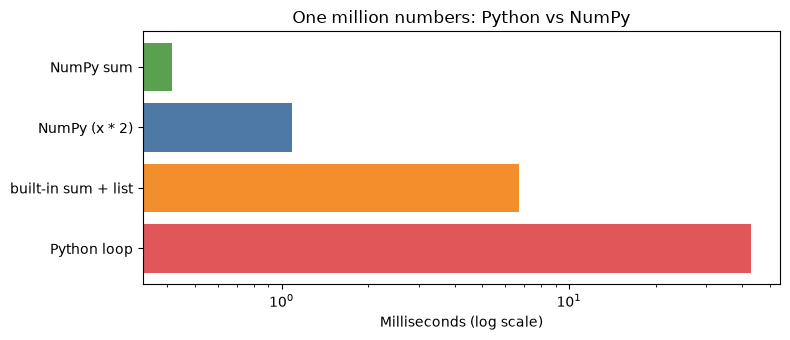

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(list(timings), list(timings.values()), color=["#E15759", "#F28E2B", "#4E79A7", "#59A14F"])
ax.set(xscale="log", title="One million numbers: Python vs NumPy", xlabel="Milliseconds (log scale)")
plt.tight_layout()
plt.show()

NumPy is one to two orders of magnitude faster and uses several times less memory. The pattern of this module: **express the work as operations on whole arrays** (vectorisation), not as Python loops over elements.

## 2. Create Arrays

| Function | Result |
| :--- | :--- |
| `np.array([1, 2, 3])` | from a list (or nested lists for 2-D) |
| `np.zeros((2, 3))`, `np.ones(5)`, `np.full(4, 7.0)` | filled arrays |
| `np.arange(0, 10, 2)` | like `range`: 0, 2, 4, 6, 8 |
| `np.linspace(0, 1, 5)` | 5 evenly spaced values, end included |
| `np.eye(3)` | identity matrix |
| `rng = np.random.default_rng(seed)` | the modern random generator; `rng.normal`, `rng.integers`, `rng.choice` |

In [4]:
rng = np.random.default_rng(42)              # a seeded generator gives reproducible results
examples = {
    "np.array([[1, 2, 3], [4, 5, 6]])": np.array([[1, 2, 3], [4, 5, 6]]),
    "np.arange(0, 10, 2)": np.arange(0, 10, 2),
    "np.linspace(0, 1, 5)": np.linspace(0, 1, 5),
    "np.zeros((2, 3))": np.zeros((2, 3)),
    "rng.integers(1, 7, size=8)  # dice": rng.integers(1, 7, size=8),
    "rng.normal(0, 1, 4).round(3)": rng.normal(0, 1, 4).round(3),
}
for label, arr in examples.items():
    print(f"{label:<36} -> {arr.tolist()}")

np.array([[1, 2, 3], [4, 5, 6]])     -> [[1, 2, 3], [4, 5, 6]]
np.arange(0, 10, 2)                  -> [0, 2, 4, 6, 8]
np.linspace(0, 1, 5)                 -> [0.0, 0.25, 0.5, 0.75, 1.0]
np.zeros((2, 3))                     -> [[0.0, 0.0, 0.0], [0.0, 0.0, 0.0]]
rng.integers(1, 7, size=8)  # dice   -> [1, 5, 4, 3, 3, 6, 1, 5]
rng.normal(0, 1, 4).round(3)         -> [-1.951, -1.302, 0.128, -0.316]


## 3. Array Metadata

| Attribute | Meaning |
| :--- | :--- |
| `shape` | size of each dimension, e.g. `(4, 365)` |
| `ndim` | number of dimensions |
| `size` | total number of elements |
| `dtype` | type of every element, e.g. `float64` |
| `itemsize` | bytes per element |
| `nbytes` | total bytes = `size * itemsize` |

The cell turns the weather columns into arrays and builds a 2-D array with one row per variable.

In [5]:
temp_max = weather["temp_max"].to_numpy()
measures = weather[["precipitation", "temp_max", "temp_min", "wind"]].to_numpy().T     # 4 rows x 1461 days

for name, arr in [("temp_max", temp_max), ("measures", measures)]:
    print(f"{name:<9} shape={arr.shape!s:<11} ndim={arr.ndim} size={arr.size:<5} dtype={arr.dtype} "
          f"itemsize={arr.itemsize} nbytes={arr.nbytes:,}")
print(f"\nhottest day: {temp_max.max()} °C, coldest maximum: {temp_max.min()} °C, mean: {temp_max.mean():.1f} °C")

temp_max  shape=(1461,)     ndim=1 size=1461  dtype=float64 itemsize=8 nbytes=11,688
measures  shape=(4, 1461)   ndim=2 size=5844  dtype=float64 itemsize=8 nbytes=46,752

hottest day: 35.6 °C, coldest maximum: -1.6 °C, mean: 16.4 °C


## 4. Data Types

Every array has exactly one `dtype`. Smaller types save memory but have limits:

| dtype | Range / precision | Bytes |
| :--- | :--- | :-: |
| `int8` | −128 … 127 | 1 |
| `int32` | about ±2.1 billion | 4 |
| `int64` | about ±9.2 × 10¹⁸ | 8 |
| `float16` | about 3 significant digits | 2 |
| `float32` | about 7 significant digits | 4 |
| `float64` | about 16 significant digits | 8 |
| `bool` | True / False | 1 |

Integer arrays **wrap around** silently when a result is too large (overflow). Floats lose precision when they are too small.

In [6]:
small = np.array([100, 120], dtype=np.int8)
with np.errstate(over="ignore"):                  # NumPy warns about scalar overflow; we show the result on purpose
    print("int8 100 + 120  ->", (small[0] + small[1]), "(overflow: wrapped around)")
print("int8 array sum  ->", small + small, "(arrays wrap around without any warning)")
print("float16 2048 + 1 ->", np.float16(2048) + np.float16(1), "(precision: the 1 is lost)")
print("float32 0.1 * 3  ->", np.float32(0.1) * 3, "| float64:", 0.1 * 3)

sizes = {dt: temp_max.astype(dt).nbytes for dt in ["float64", "float32", "float16"]}
errors = {dt: np.abs(temp_max.astype(dt).astype("float64") - temp_max).max() for dt in sizes}
print("\n" + "\n".join(f"{dt}: {sizes[dt]:>6,} bytes, max rounding error {errors[dt]:.4f} °C" for dt in sizes))

int8 100 + 120  -> -36 (overflow: wrapped around)
int8 array sum  -> [-56 -16] (arrays wrap around without any warning)
float16 2048 + 1 -> 2.048e+03 (precision: the 1 is lost)
float32 0.1 * 3  -> 0.3 | float64: 0.30000000000000004

float64: 11,688 bytes, max rounding error 0.0000 °C
float32:  5,844 bytes, max rounding error 0.0000 °C
float16:  2,922 bytes, max rounding error 0.0125 °C


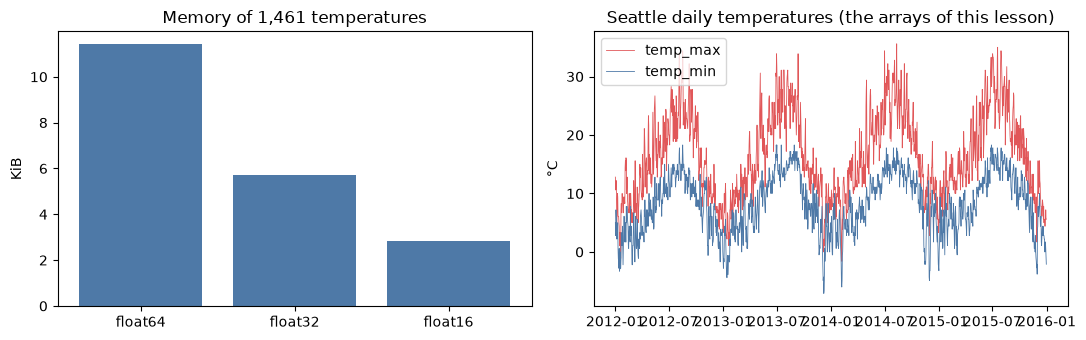

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.bar(sizes.keys(), [v / 1024 for v in sizes.values()], color="#4E79A7")
ax1.set(title="Memory of 1,461 temperatures", ylabel="KiB")
ax2.plot(weather["date"], temp_max, lw=0.6, color="#E15759", label="temp_max")
ax2.plot(weather["date"], weather["temp_min"].to_numpy(), lw=0.6, color="#4E79A7", label="temp_min")
ax2.set(title="Seattle daily temperatures (the arrays of this lesson)", ylabel="°C")
ax2.legend()
plt.tight_layout()
plt.show()

`float32` halves the memory with errors far below the measurement precision (0.1 °C). Deep learning uses `float32`, `float16` and `bfloat16` for this reason (M20). For money and counts that must be exact, use integers or decimal types.

*Insight: Think of an array as a typed block of memory: its `shape` describes the grid, its `dtype` decides memory and precision. Choose the smallest dtype that is safe for the value range, and replace Python loops with whole-array operations.*

## Real-World Use Case or Analogy

A Python list is like a **notebook of sticky notes**, each note in a different drawer of the office: flexible, but you walk to every drawer. A NumPy array is like a **printed table on one sheet**: every cell has the same size and format, so you can scan a whole column at once.

Images (height × width × colour channels), audio signals, sensor streams, embeddings and neural-network weights are all stored as arrays. Learning NumPy's model of shape and dtype makes pandas, PyTorch and JAX much easier to understand.